In [22]:
import awkward as ak
import numba
import numpy as np
import pandas as pd
import awkward as ak
import vector
import torch
from scipy.special import softmax
vector.register_numba()
vector.register_awkward()
import os

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import mplhep as hep
hep.style.use(hep.style.ROOT)

#from importlib import Softmax

import numba
import h5py
import yaml

import seaborn as sns
from sklearn.metrics import confusion_matrix

In [44]:
def plot_confusion_matrix(y_true, y_pred, class_names=None, title='Confusion Matrix', cmap='Blues'):
    """
    Plots the confusion matrix.
    Args:
    y_true (array-like): Ground truth (correct) target values.
    y_pred (array-like): Estimated targets as returned by a classifier.
    class_names (list of str, optional): List of class names to be displayed
                                         on the axes. Defaults to None.
    title (str, optional): Title of the plot. Defaults to 'Confusion Matrix'.
    cmap (str, optional): Colormap to be used for the plot. Defaults to 'Blues'.
    """
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    
    if class_names is not None:
        labels = class_names
    else:
        labels = np.arange(cm.shape[0])
    
    plt.figure(figsize=(12, 12), dpi=100)
    sns.heatmap(cm, annot=True, cmap=cmap, xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

In [8]:
import onnxruntime    # to inference ONNX models, we use the ONNX Runtime
sess_options = onnxruntime.SessionOptions()

sess_options.intra_op_num_threads = 4
sess_options.intra_op_num_threads = 4
sess_options.execution_mode = onnxruntime.ExecutionMode.ORT_PARALLEL
sess_options.graph_optimization_level = onnxruntime.GraphOptimizationLevel.ORT_ENABLE_ALL


session = onnxruntime.InferenceSession(
    "/eos/home-g/gbonomel/tth/spanet/models/multiclassifier_Run3_weights/spanet_v2.onnx", 
    sess_options = sess_options,
    providers=['CUDAExecutionProvider', 'CPUExecutionProvider']
)

for input in session.get_inputs():
    print(f"{input.name}, {input.shape}")
    
for output in session.get_outputs():
    print(f"{output.name}, {output.shape}")


Jet_data, ['batch_size', 'num_Jet', 9]
Jet_mask, ['batch_size', 'num_Jet']
Met_data, ['batch_size', 'num_Met', 3]
Met_mask, ['batch_size', 'num_Met']
Lepton_data, ['batch_size', 'num_Lepton', 3]
Lepton_mask, ['batch_size', 'num_Lepton']
Event_data, ['batch_size', 'num_Event', 1]
Event_mask, ['batch_size', 'num_Event']
t1_assignment_probability, ['Expt1_assignment_probability_dim_0', 'Expt1_assignment_probability_dim_1', 'Expt1_assignment_probability_dim_2', 'Expt1_assignment_probability_dim_3']
t2_assignment_probability, ['Expt2_assignment_probability_dim_0', 'Expt2_assignment_probability_dim_1']
h_assignment_probability, ['Exph_assignment_probability_dim_0', 'Exph_assignment_probability_dim_1', 'Exph_assignment_probability_dim_2']
t1_detection_probability, ['Sigmoidt1_detection_probability_dim_0']
t2_detection_probability, ['Sigmoidt2_detection_probability_dim_0']
h_detection_probability, ['Sigmoidh_detection_probability_dim_0']
EVENT/signal, ['SoftmaxEVENT/signal_dim_0', 7]


/cvmfs/sft.cern.ch/lcg/views/LCG_107_swan/x86_64-el9-gcc13-opt/lib/python3.11/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:115: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'CPUExecutionProvider'
  warnings.warn(


In [9]:
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/non_semileptonic_tthbb_export/h5_files/tthbb_genmatched_ttbb_tthbb_non_semilep_test_1088450.h5"
config = "/eos/home-g/gbonomel/tth/spanet/models/multiclassifier_Run3_weights/spanet_output/version_0/event.yaml"

In [61]:
f = h5py.File(h5_file, 'r')
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [63]:
jet_data = f["INPUTS"]["Jet"]
met_data = f["INPUTS"]["Met"]
lepton_data = f["INPUTS"]["Lepton"]
event_data = f["INPUTS"]["Event"]
weights = f["WEIGHTS"]["weight"]

In [66]:
weights[()]

array([0.05217322, 0.05831229, 0.03531294, ..., 0.0230327 , 0.04069727,
       0.10741478], dtype=float32)

In [12]:
with open(config, 'r') as file:
    data = yaml.safe_load(file)

jet_inputs    = list(data['INPUTS']['SEQUENTIAL']['Jet'].keys())
met_inputs    = data['INPUTS']['GLOBAL']['Met']
lepton_inputs = data['INPUTS']['GLOBAL']['Lepton']
event_inputs  = data['INPUTS']['GLOBAL']['Event']


    

In [13]:
jet_input = np.stack([jet_data[j][()] for j in jet_inputs], axis=2)
met_input = np.stack([met_data[j][()] for j in met_inputs], axis=1)[:,None,:]
lepton_input = np.stack([lepton_data[j][()] for j in lepton_inputs], axis=1)[:,None,:]
event_input = np.stack([event_data[j][()] for j in event_inputs], axis=1)[:,None,:]

In [14]:
jet_input[:,:,0] = np.log(1+ jet_input[:,:,0])
met_input[:,:,0] = np.log(1+ met_input[:,:,0])
lepton_input[:,:,0] = np.log(1+ lepton_input[:,:,0])

In [15]:
jet_mask = jet_data["MASK"][()]
met_mask = np.ones(shape=[met_input.shape[0], 1]) == 1
lepton_mask = met_mask
event_mask = met_mask

In [16]:
met_mask.shape

(1088450, 1)

In [17]:
batch_size = 2048

In [20]:
Nevents = jet_input.shape[0]
cl_out= np.empty((Nevents, 7))

for i in range(Nevents//batch_size):
    output = session.run(input_feed={
        "Jet_data": jet_input[i*batch_size: (i+1)*batch_size],
        "Jet_mask": jet_mask[i*batch_size: (i+1)*batch_size],
        "Met_data": met_input[i*batch_size: (i+1)*batch_size],
        "Met_mask": met_mask[i*batch_size: (i+1)*batch_size],
        "Lepton_data": lepton_input[i*batch_size: (i+1)*batch_size],
        "Lepton_mask": lepton_mask[i*batch_size: (i+1)*batch_size],
        "Event_data": event_input[i*batch_size: (i+1)*batch_size],
        "Event_mask": event_mask[i*batch_size: (i+1)*batch_size],
        }, output_names=["EVENT/signal"]
               )
    cl_out[i*batch_size: (i+1)*batch_size] = output[0]

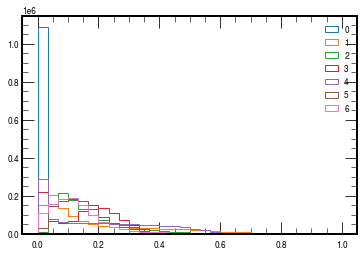

In [21]:
for i in range(7):
    plt.hist(cl_out[:,i], range=(0,1), bins=30, histtype='step', label=f"{i}")
plt.legend()
#plt.hist(cl_out[:,0])SoftmaxEVENT

In [ ]:
plt.hist(cl_out[:,1])

(array([419., 930., 363., 181.,  87.,  32.,  19.,  14.,   1.,   2.]),
 array([0.11765705, 0.13181084, 0.14596465, 0.16011846, 0.17427225,
        0.18842605, 0.20257986, 0.21673366, 0.23088746, 0.24504125,
        0.25919506]),
 <BarContainer object of 10 artists>)

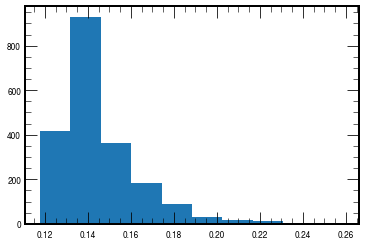

In [101]:
plt.hist(cl_out[:,2])

In [24]:
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [33]:
y_true = f["CLASSIFICATIONS"]["EVENT"]["signal"][()]

In [34]:
y_pred = np.argmax(cl_out, axis=1)

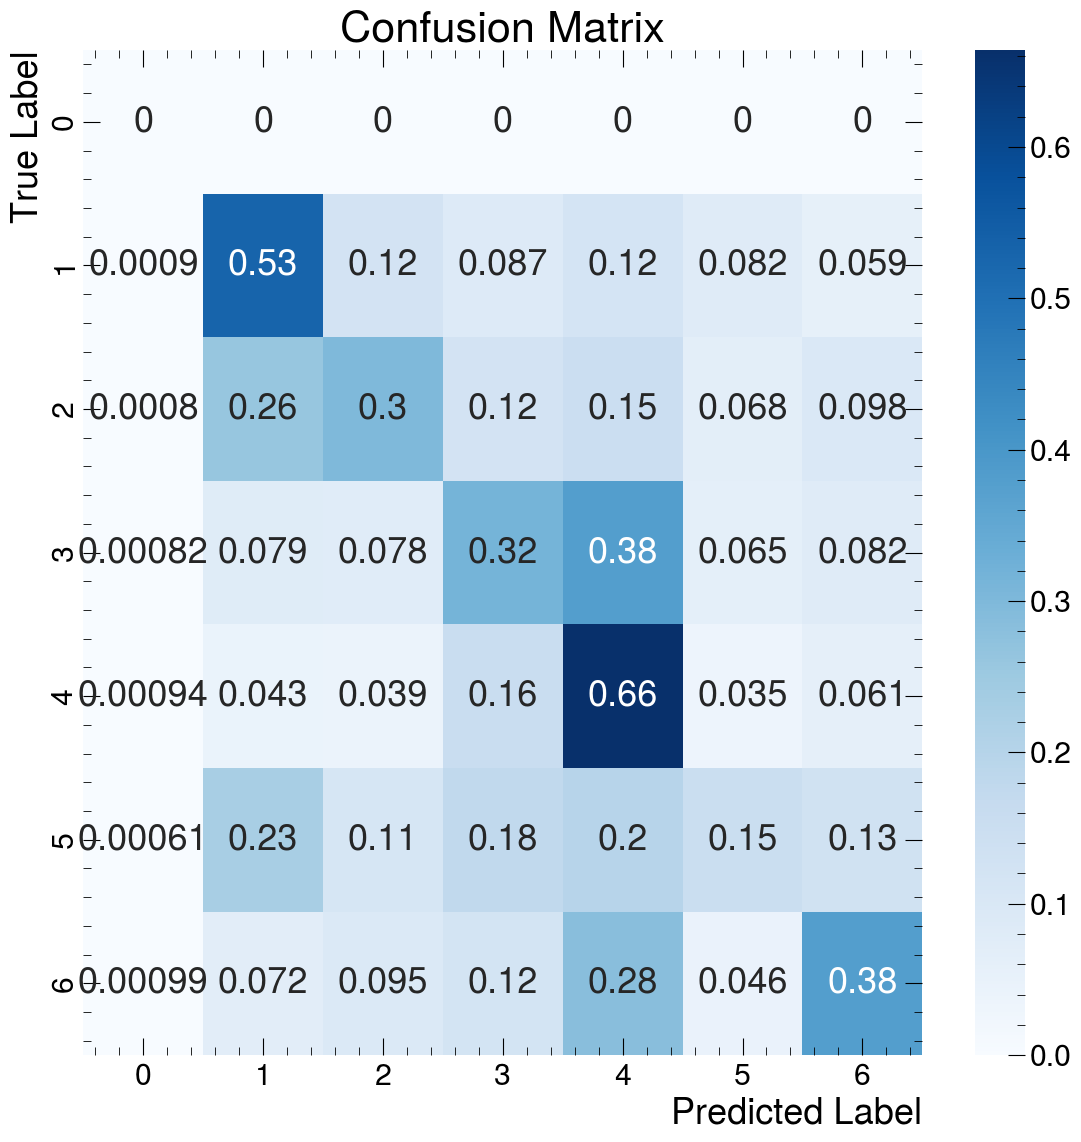

In [45]:
plot_confusion_matrix(y_true, y_pred)

In [83]:
labels = ["ttHbb", "ttbb", "ttcc", "ttlf", "ttV", "singleTop"]

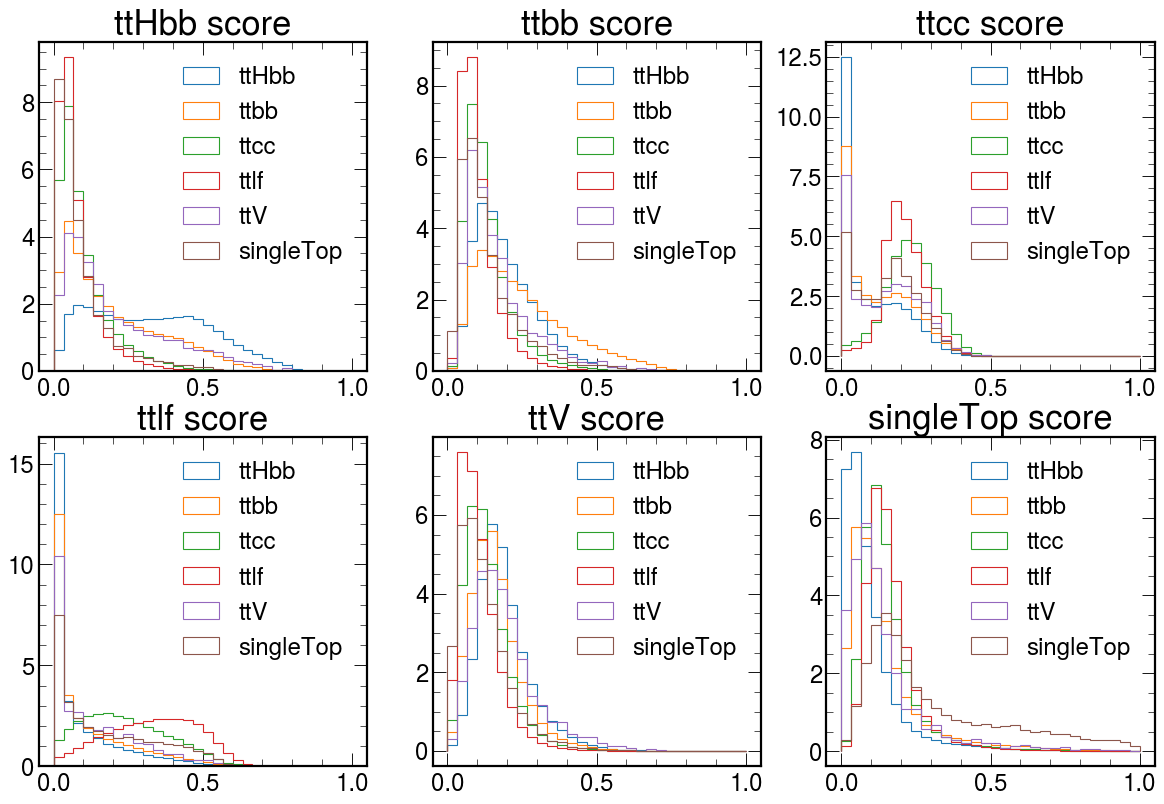

In [90]:
plt.figure(figsize=(18, 12), dpi=80)
for i in range(1,7):
    plt.subplot(2,3, i)
    for cl in range(1,7):
        mask = y_true == cl
        plt.hist(cl_out[mask,i], weights=weights[mask], range=(0,1), bins=30, histtype='step', label=labels[cl-1], density=True)
    #plt.xlabel("score")
    plt.title(f"{labels[i-1]} score")
    plt.legend()

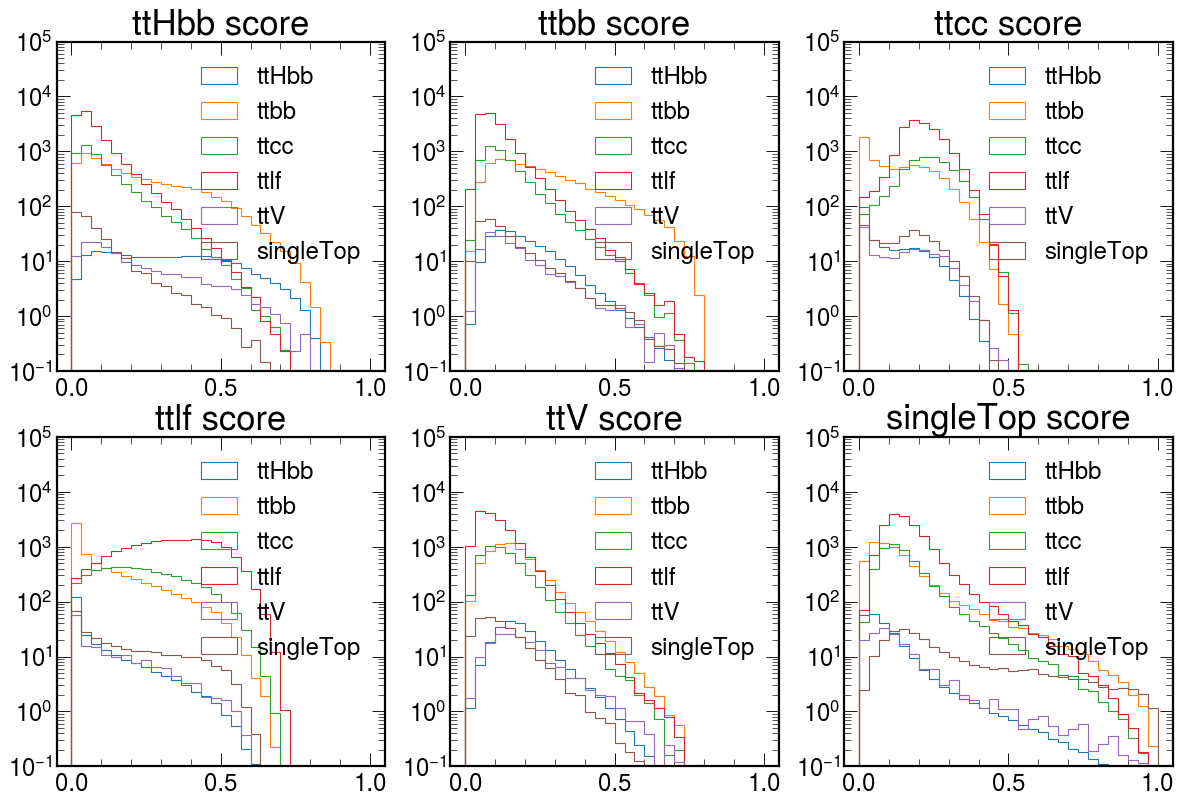

In [91]:
plt.figure(figsize=(18, 12), dpi=80)
for i in range(1,7):
    plt.subplot(2,3, i)
    for cl in range(1,7):
        mask = y_true == cl
        plt.hist(cl_out[mask,i], weights=weights[mask], range=(0,1), bins=30, histtype='step', label=labels[cl-1])
    #plt.xlabel(f"score {i}")
    plt.yscale("log")
    plt.title(f"{labels[i-1]} score")
    plt.ylim(1e-1, 1e5)
    plt.legend()

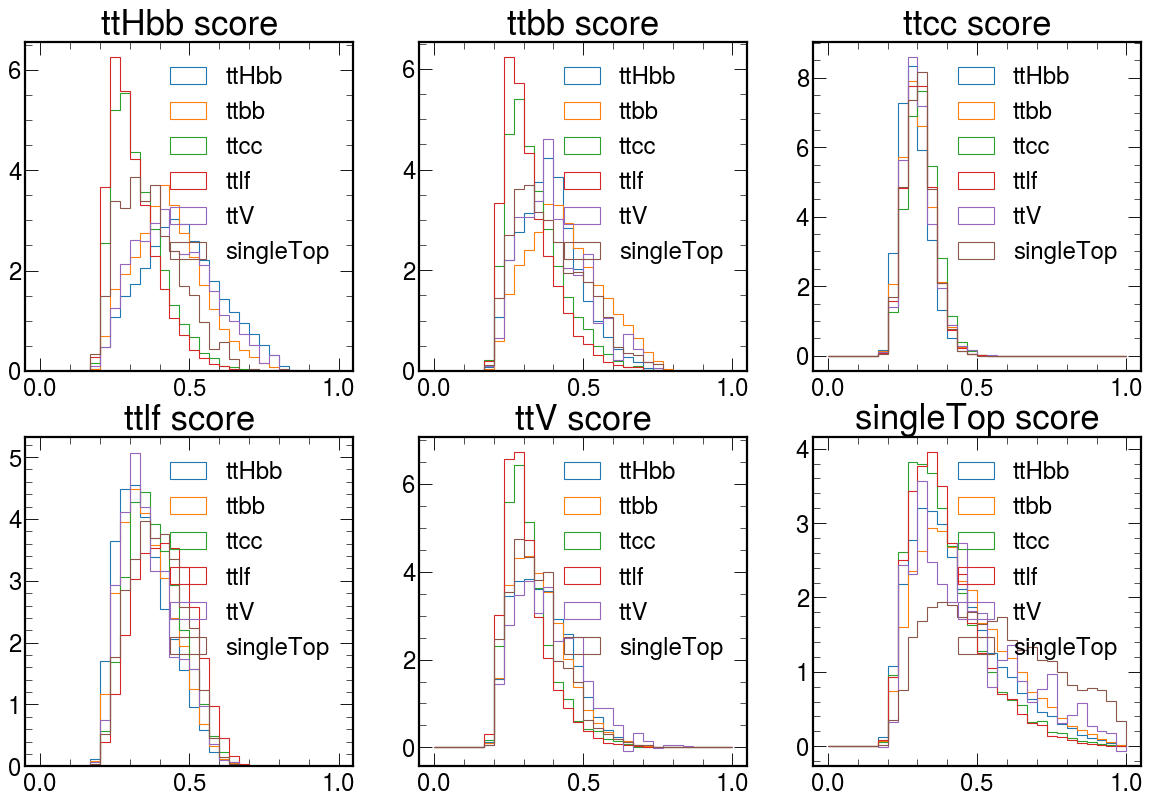

In [92]:
plt.figure(figsize=(18, 12), dpi=80)
for i in range(1,7):
    region_mask = np.argmax(cl_out, axis=1) == i
    
    plt.subplot(2,3, i)
    for cl in range(1,7):
        mask = y_true == cl
        plt.hist(cl_out[mask&region_mask,i], weights=weights[mask&region_mask], range=(0,1), bins=30, histtype='step', label=labels[cl-1], density=True)
    #plt.xlabel(f"score {i}")
    plt.title(f"{labels[i-1]} score")
    plt.legend()

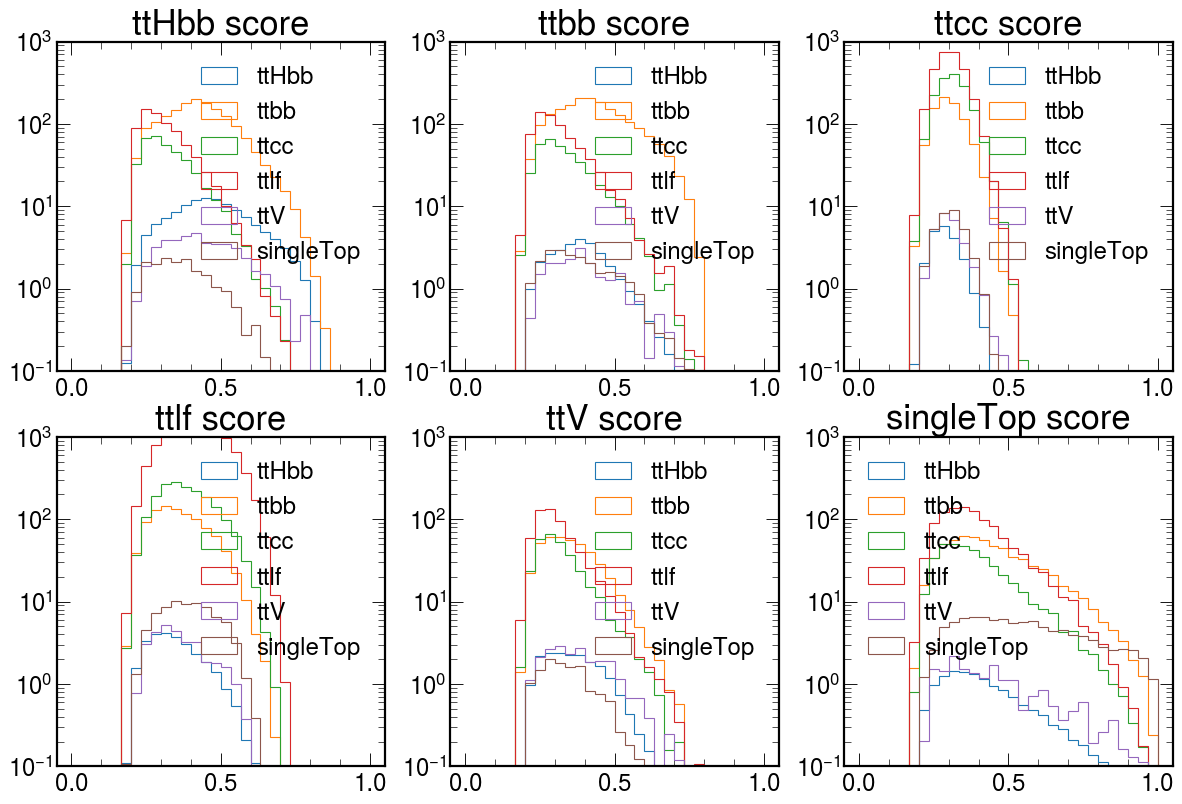

In [95]:
plt.figure(figsize=(18, 12), dpi=80)
for i in range(1,7):
    region_mask = np.argmax(cl_out, axis=1) == i
    
    plt.subplot(2,3, i)
    for cl in range(1,7):
        mask = y_true == cl
        plt.hist(cl_out[mask&region_mask,i], weights=weights[mask&region_mask], range=(0,1), bins=30, histtype='step', label=labels[cl-1])
    #plt.xlabel(f"score {i}")
    plt.yscale("log")
    plt.title(f"{labels[i-1]} score")
    plt.ylim(1e-1, 1e3)
    plt.legend()

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_correlation_matrix_numpy(numpy_array, feature_names=None, title="Correlation Matrix", annot=True, cmap="coolwarm"):
    """
    Plots the correlation matrix from a NumPy array.

    Args:
        numpy_array (np.ndarray): A NumPy array of shape [N, M], where M is the
                                   number of features.
        feature_names (list of str, optional): List of feature names to be used as
                                               labels for the plot. Defaults to None.
        title (str, optional): Title of the plot. Defaults to "Correlation Matrix".
        annot (bool, optional): Whether to display correlation coefficients in the
                                heatmap. Defaults to True.
        cmap (str, optional): Colormap to use for the heatmap. Defaults to "coolwarm".
    """

    num_features = numpy_array.shape[1]
    if feature_names is None:
        feature_names = [f'Feature {i+1}' for i in range(num_features)]
    elif len(feature_names) != num_features:
        raise ValueError(f"Length of feature_names ({len(feature_names)}) must match the number of features in the array ({num_features}).")

    # Convert NumPy array to pandas DataFrame
    df = pd.DataFrame(numpy_array, columns=feature_names)

    # Calculate the correlation matrix
    corr_matrix = df.corr()

    # Create the heatmap
    plt.figure(figsize=(12,12), dpi=100)  # Adjust figure size dynamically
    sns.heatmap(corr_matrix, annot=annot, cmap=cmap, xticklabels=feature_names, yticklabels=feature_names)
    plt.title(title)
    plt.tight_layout()
    plt.show()

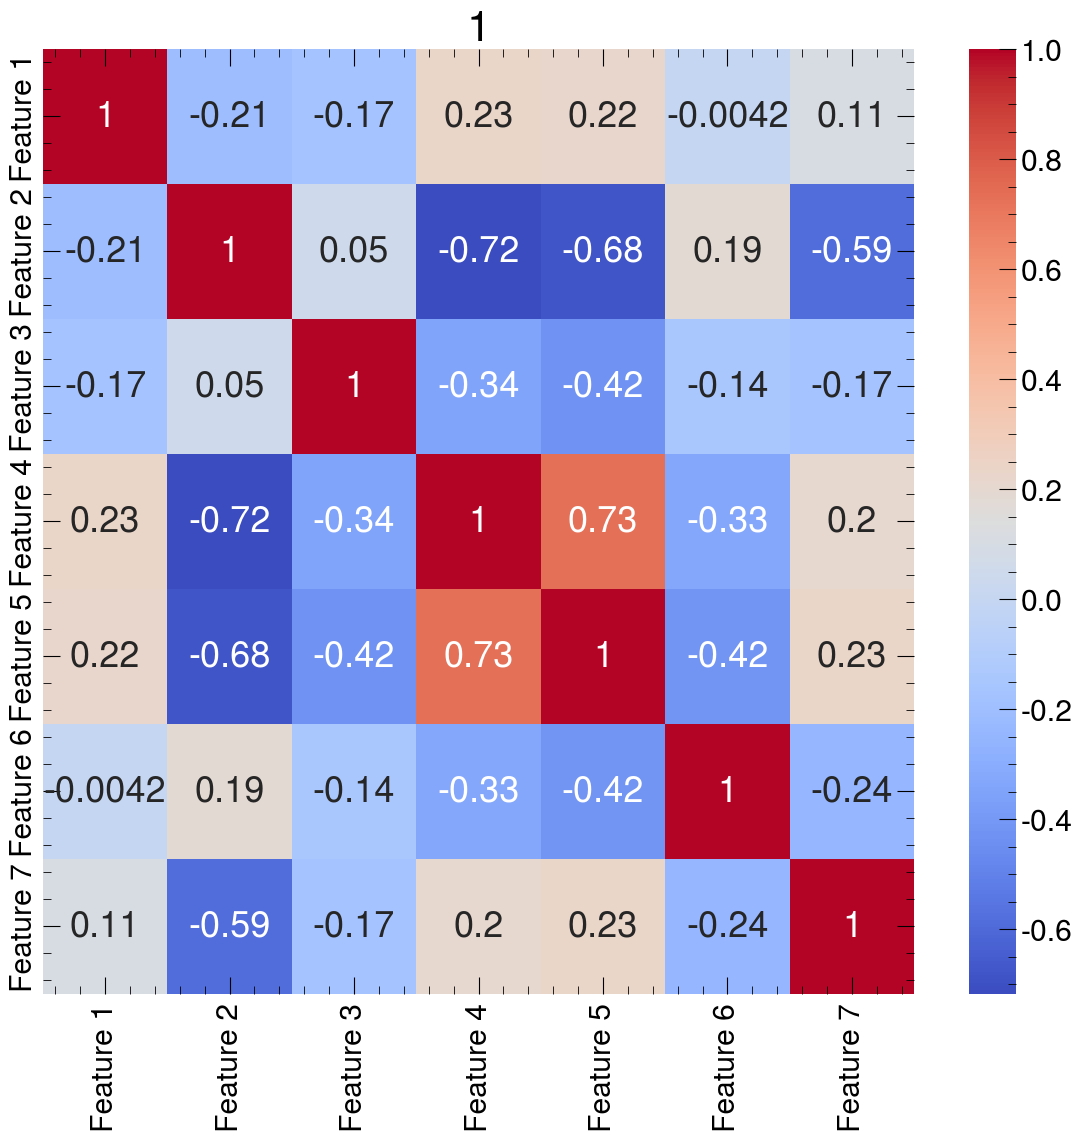

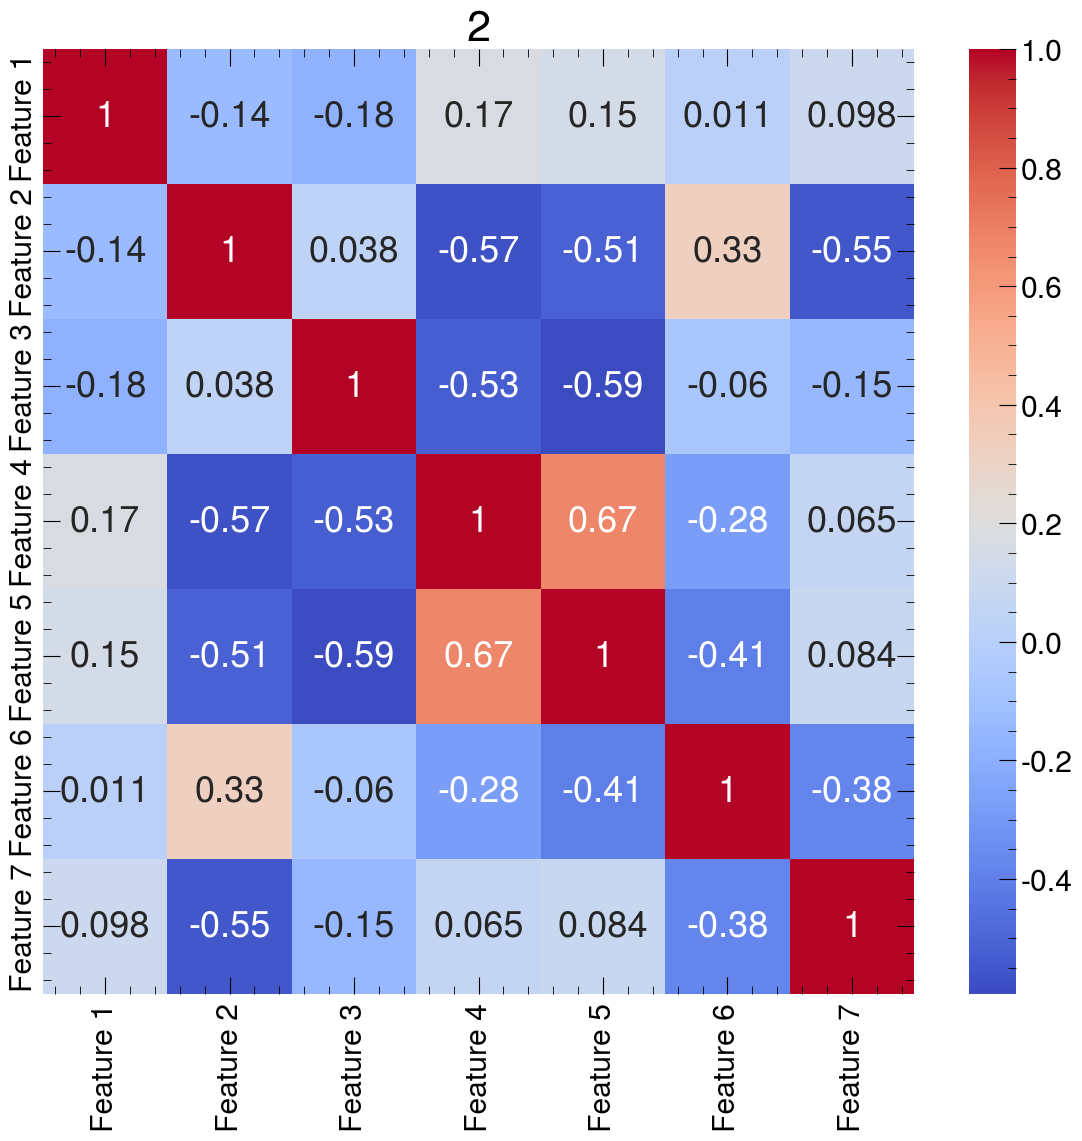

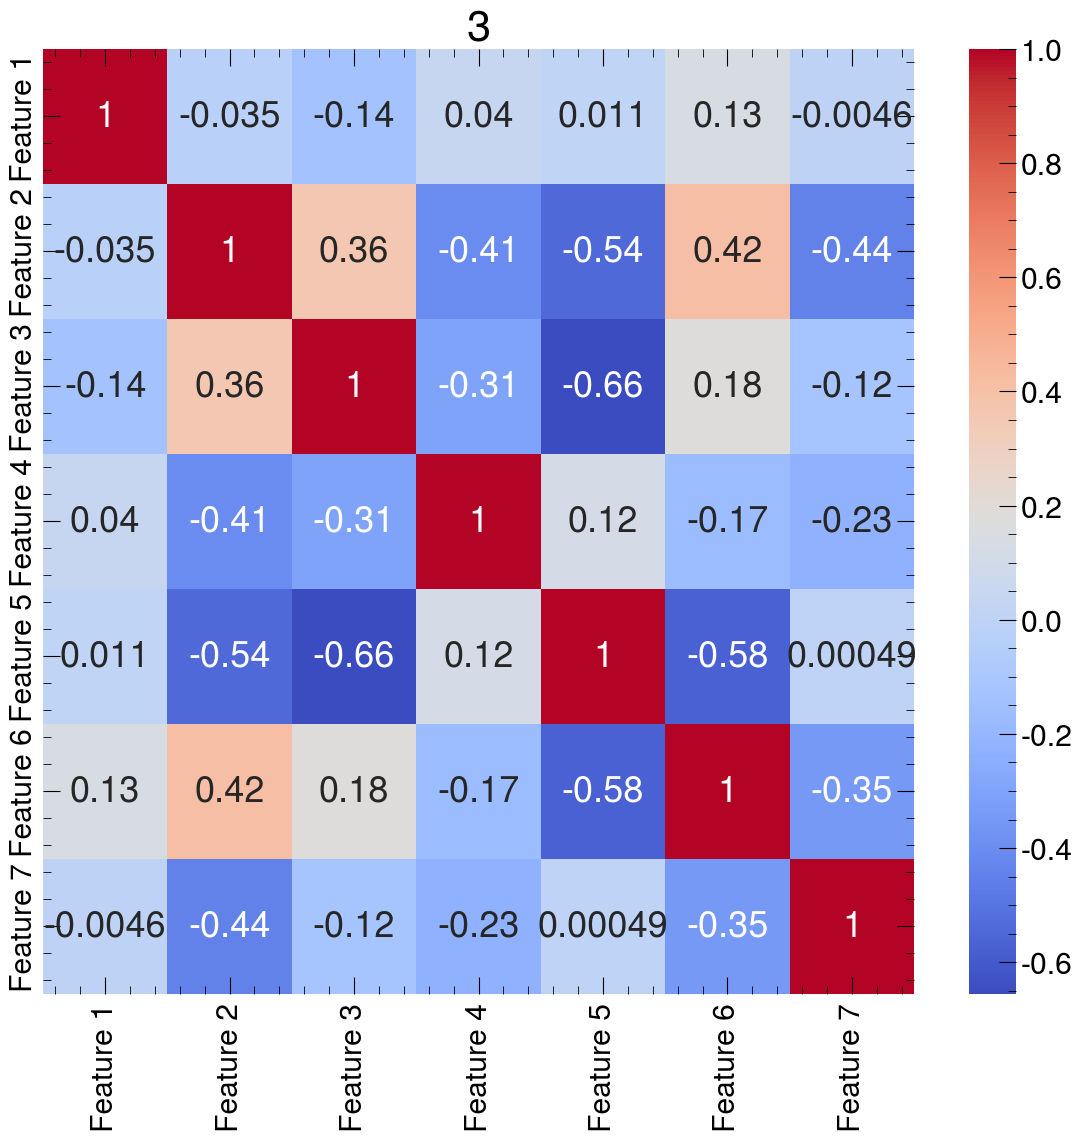

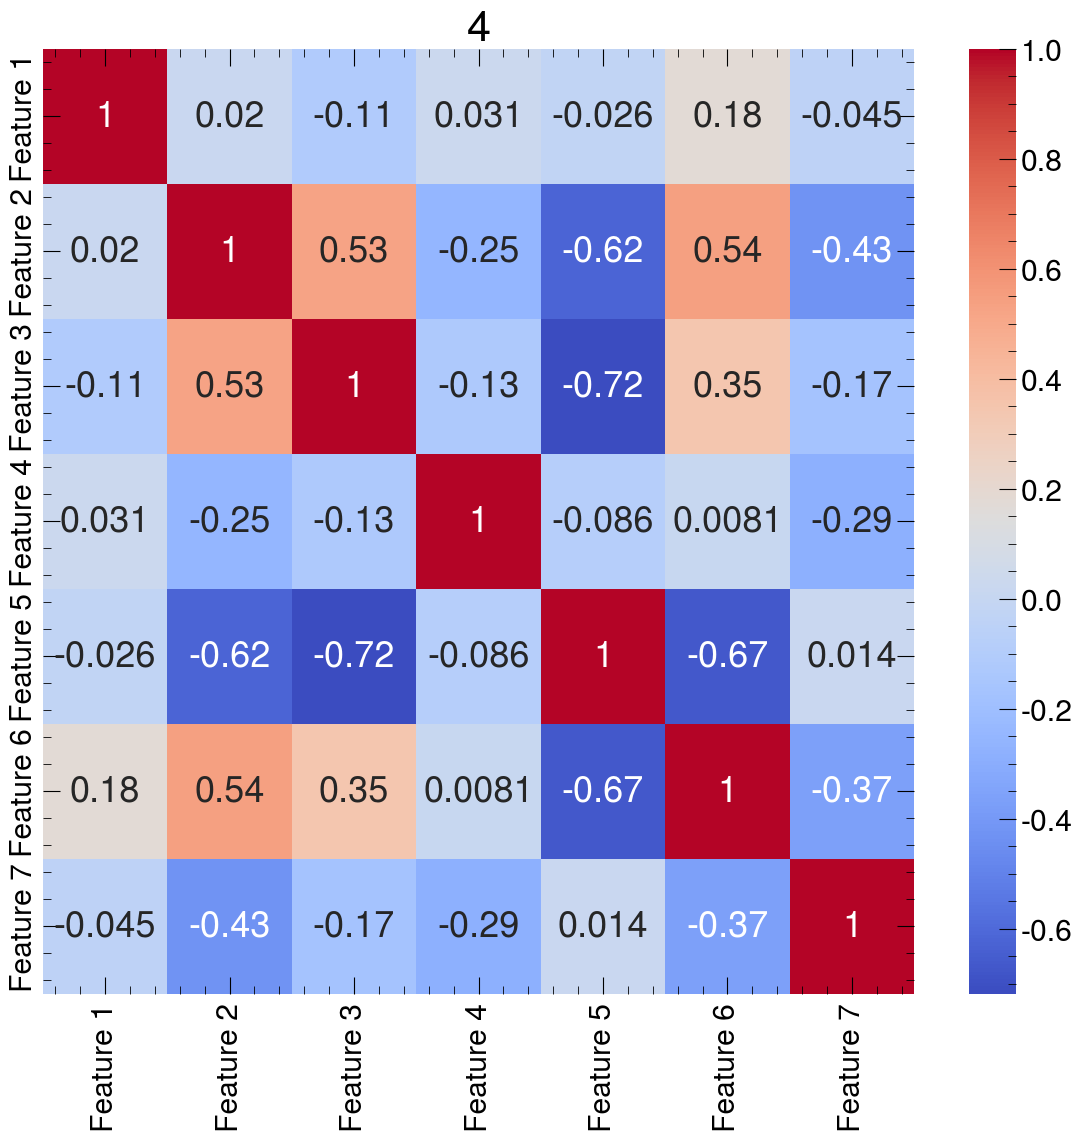

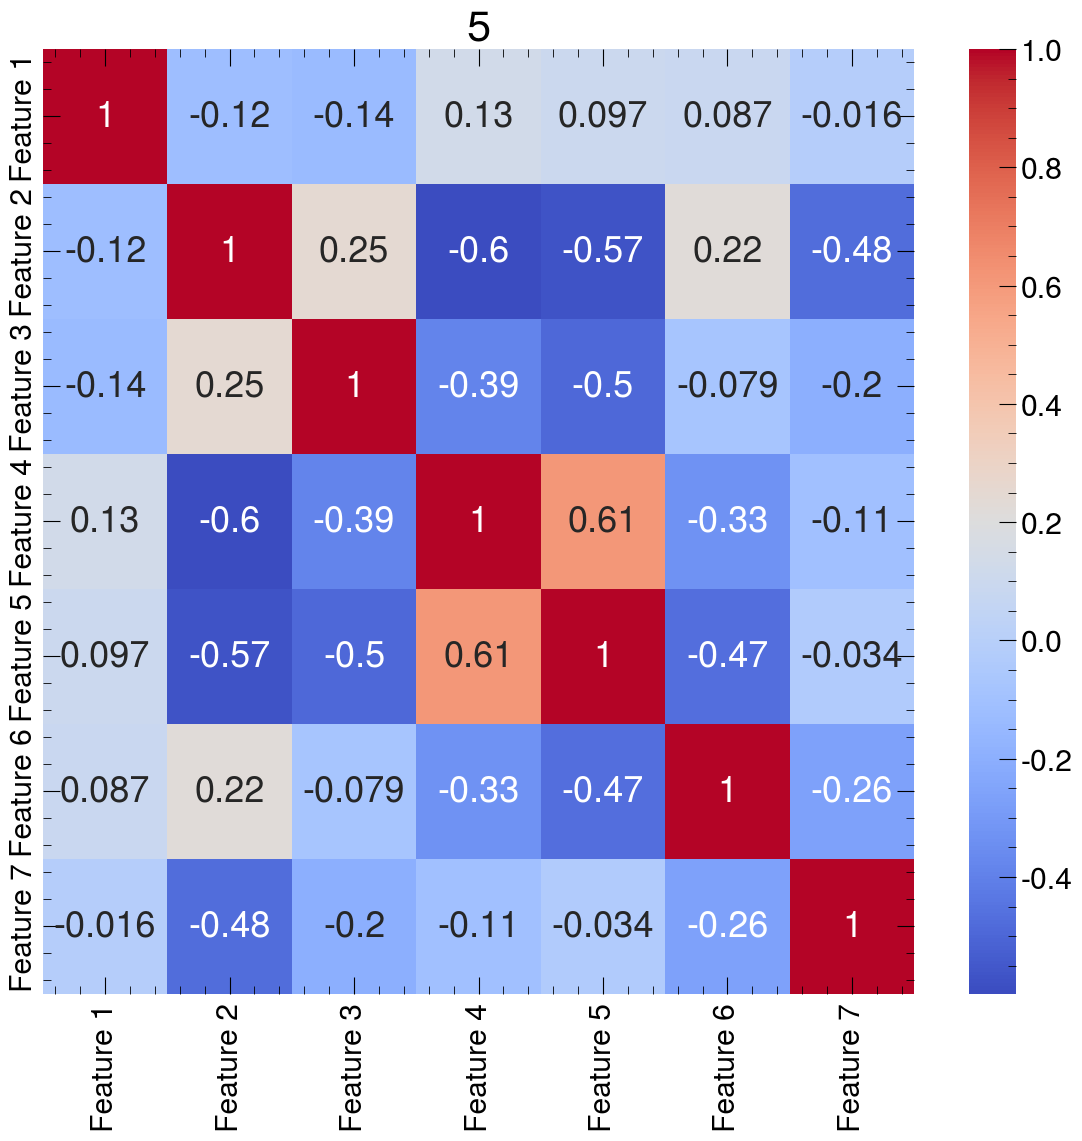

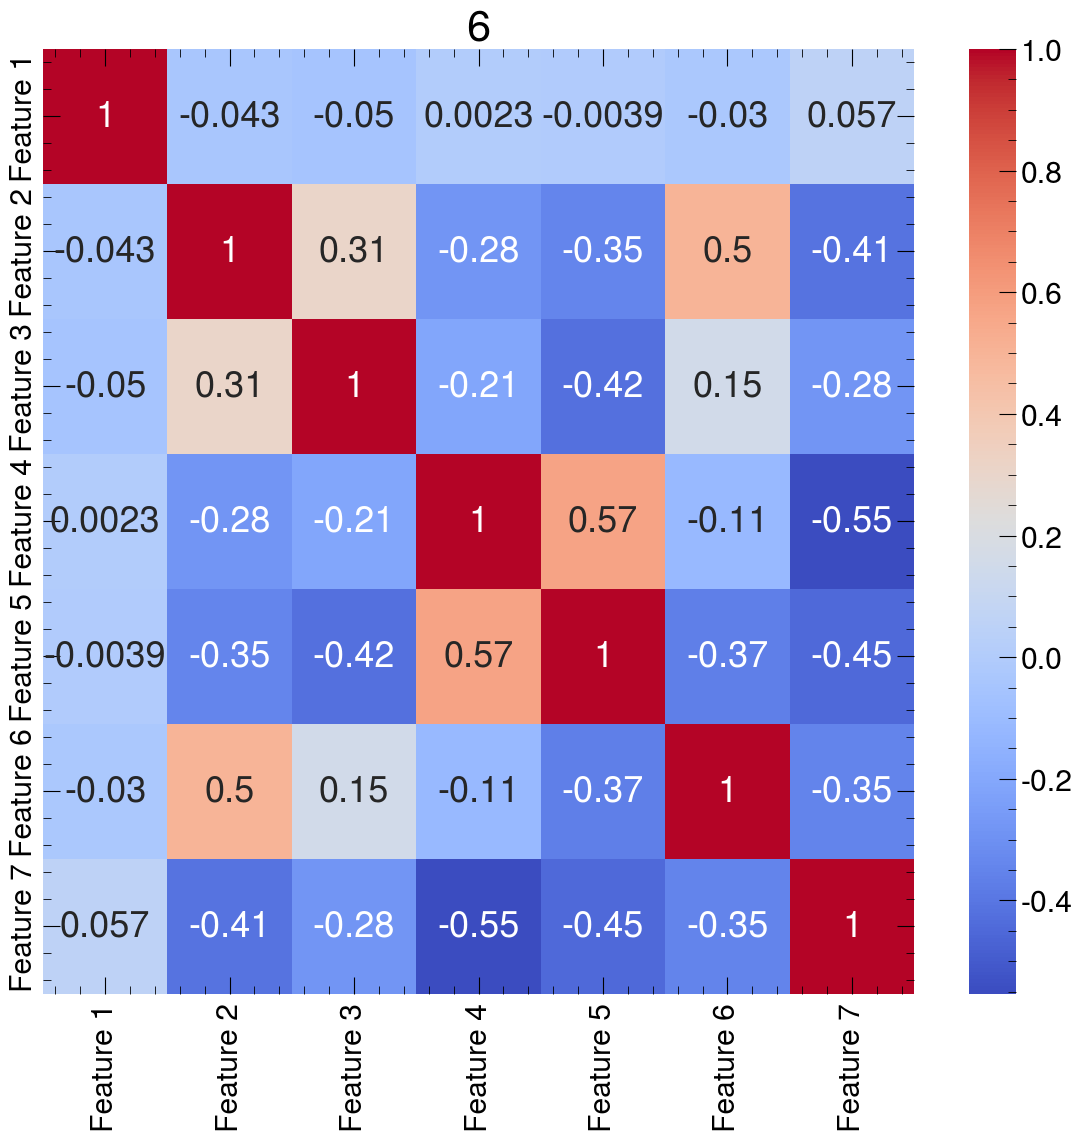

In [82]:
#for i in range(1,7):
#plt.subplot(2,3, i)
for cl in range(1,7):
    mask = y_true == cl
    plot_correlation_matrix_numpy(cl_out[mask],title=f"{cl}")
#plt.xlabel(f"score {i}")
#plt.legend()

In [ ]:
f, axs = plt.subplots(6,6, figsize=(36, 36), dpi=200)

for i, icol in enumerate(columns):
    for j, jcol in enumerate(columns):
        x = X[icol]
        y = X[jcol]
        if i == j:
            axs[i][j].hist(x, bins=100)
            if j == 5:
                axs[i][j].set_xlabel(f"Feature {i}")
            if i == 0:
                axs[i][j].set_ylabel(f"Feature {i}")
        elif j>i:
            axs[i][j].remove()
        else:
            axs[i][j].hist2d(y, x, bins=60, cmap="viridis", cmin=1)
            if i == 5:
                axs[i][j].set_xlabel(f"Feature {j}")
            if j == 0:
                axs[i][j].set_ylabel(f"Feature {i}")